# Adaptive Client Probing for Federated Learning

Reinforcement Learning for Adaptive Client Probing and Selection in Federated Learning.

This notebook simulates federated learning and compares three ways of deciding which clients to assess before training:

1. **Always probe**: every candidate client trains one epoch before selection (the fixed-probing pipeline used by FedMarl-style methods).
2. **UCB-CS**: bandit-based selection that relies only on discounted historical losses and never probes.
3. **Adaptive probing (proposed)**: one RL agent per client chooses among `skip`, `use_history`, and `probe`.

Dataset: Fashion-MNIST, split across clients with a Dirichlet label skew.

Resource cost is simulated (not wall-clock): each client has a random compute speed and communication cost.

Clients that have never been observed start with a prior loss equal to ln(10).


In [1]:
import copy
import math
import random
from collections import deque
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


## 1. Configuration

All tunable values. The reward weights and the simulated cost ranges are the most important ones for the research question, because they define the accuracy versus resource trade-off.

In [2]:
@dataclass
class Config:
    # Federation
    num_clients: int = 20
    clients_per_round: int = 5
    local_epochs: int = 4
    batch_size: int = 64
    learning_rate: float = 0.05
    dirichlet_alpha: float = 0.5
    min_client_samples: int = 100
    rounds_per_episode: int = 30
    validation_size: int = 5000

    # Simulated client resources
    min_compute_speed: float = 0.5
    max_compute_speed: float = 2.0
    min_comm_cost: float = 0.2
    max_comm_cost: float = 1.0

    # RL controller
    rl_train_episodes: int = 100
    rl_gamma: float = 0.9
    rl_learning_rate: float = 1e-3
    rl_batch_size: int = 32
    rl_buffer_size: int = 2000
    rl_target_sync_every: int = 50
    rl_epsilon_start: float = 1.0
    rl_epsilon_end: float = 0.05
    accuracy_reward_scale: float = 10.0
    cost_penalty_weight: float = 0.5

    # UCB-CS baseline
    ucb_discount: float = 0.9
    ucb_exploration_scale: float = 0.5

    # Seeds
    federation_seed: int = 0
    train_seed_base: int = 1000
    eval_seeds: tuple = (100, 101, 102)


CFG = Config()
NUM_CLASSES = 10


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

## 2. Data and federation

The training set is split into a validation set (used for the RL reward) and a training set (split across clients). The test set is only used for final reporting.

The federation (who owns which data, and each client's speed and communication cost) is fixed by `federation_seed`. Episode seeds only change model initialization and batch order.

In [3]:
def load_fashion_mnist(cfg):
    train = datasets.FashionMNIST("data", train=True, download=True)
    test = datasets.FashionMNIST("data", train=False, download=True)

    def to_tensors(dataset):
        # Normalization constants are the published Fashion-MNIST mean and standard deviation.
        x = dataset.data.float().div(255.0).sub(0.2860).div(0.3530).unsqueeze(1)
        return x.to(DEVICE), dataset.targets.clone().to(DEVICE)

    x_train, y_train = to_tensors(train)
    x_test, y_test = to_tensors(test)

    generator = torch.Generator().manual_seed(cfg.federation_seed)
    order = torch.randperm(len(x_train), generator=generator).to(DEVICE)
    val_idx = order[: cfg.validation_size]
    train_idx = order[cfg.validation_size:]

    return {
        "x_train": x_train[train_idx],
        "y_train": y_train[train_idx],
        "x_val": x_train[val_idx],
        "y_val": y_train[val_idx],
        "x_test": x_test,
        "y_test": y_test,
    }


def dirichlet_partition(labels, cfg, rng):
    labels = labels.cpu().numpy()
    while True:
        client_indices = [[] for _ in range(cfg.num_clients)]
        for cls in np.unique(labels):
            class_idx = np.where(labels == cls)[0]
            rng.shuffle(class_idx)
            proportions = rng.dirichlet(cfg.dirichlet_alpha * np.ones(cfg.num_clients))
            cut_points = (np.cumsum(proportions) * len(class_idx)).astype(int)[:-1]
            for client, part in enumerate(np.split(class_idx, cut_points)):
                client_indices[client].extend(part.tolist())
        # Redraw instead of padding so that the label skew stays a pure Dirichlet draw.
        if min(len(ix) for ix in client_indices) >= cfg.min_client_samples:
            return [torch.tensor(sorted(ix), device=DEVICE) for ix in client_indices]


@dataclass
class ClientProfile:
    num_samples: int
    epoch_cost: float
    comm_cost: float


def build_profiles(partitions, cfg, rng):
    mean_samples = np.mean([len(p) for p in partitions])
    profiles = []
    for partition in partitions:
        speed = rng.uniform(cfg.min_compute_speed, cfg.max_compute_speed)
        comm = rng.uniform(cfg.min_comm_cost, cfg.max_comm_cost)
        # Cost is relative to an average-sized client on a speed 1.0 device.
        epoch_cost = (len(partition) / mean_samples) / speed
        profiles.append(ClientProfile(len(partition), epoch_cost, comm))
    return profiles

## 3. Model and local training

In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3)
        self.conv2 = nn.Conv2d(16, 32, 3)
        self.fc1 = nn.Linear(32 * 5 * 5, 64)
        self.fc2 = nn.Linear(64, NUM_CLASSES)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = x.flatten(1)
        return self.fc2(F.relu(self.fc1(x)))


def train_one_epoch(model, x, y, cfg):
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=cfg.learning_rate)
    order = torch.randperm(len(x), device=DEVICE)
    total_loss = torch.zeros((), device=DEVICE)
    for start in range(0, len(x), cfg.batch_size):
        batch = order[start:start + cfg.batch_size]
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x[batch]), y[batch])
        loss.backward()
        optimizer.step()
        total_loss += loss.detach() * len(batch)
    # A single transfer at the end avoids a GPU sync on every batch.
    return total_loss.item() / len(x)


@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    correct = 0
    for start in range(0, len(x), 2000):
        predictions = model(x[start:start + 2000]).argmax(dim=1)
        correct += (predictions == y[start:start + 2000]).sum().item()
    return correct / len(x)


def federated_average(state_dicts, weights):
    total_weight = float(sum(weights))
    averaged = {}
    for key in state_dicts[0]:
        averaged[key] = sum(sd[key] * (w / total_weight) for sd, w in zip(state_dicts, weights))
    return averaged

## 4. Federated environment

Each round the controller supplies one action per client:

* `skip`: the client is ignored this round.
* `use_history`: the client is a candidate, ranked by its last known loss. No assessment cost is paid.
* `probe`: the client trains one epoch on the current global model and reports its loss. It is then a candidate, ranked by that fresh loss.

The top K candidates by loss participate. A probed client that is selected continues from its probe state for the remaining local epochs, so its probe epoch is not wasted. A probed client that is not selected has paid the probe cost for information only.

Cost accounting (simulated):

* probe: one epoch of that client's `epoch_cost`
* selected client: its remaining epochs of `epoch_cost` plus its `comm_cost`

In [5]:
SKIP, USE_HISTORY, PROBE = 0, 1, 2
ACTION_NAMES = ["skip", "use_history", "probe"]
NUM_ACTIONS = len(ACTION_NAMES)
OBS_DIM = 6


@dataclass
class ClientHistory:
    last_loss: float
    age: int


@dataclass
class RoundResult:
    val_accuracy: float
    accuracy_gain: float
    cost: float
    normalized_cost: float
    probed: list
    selected: list
    observed_losses: dict


class FederatedEnv:
    def __init__(self, data, cfg):
        self.cfg = cfg
        self.data = data

        rng = np.random.default_rng(cfg.federation_seed)
        partitions = dirichlet_partition(data["y_train"], cfg, rng)
        self.client_x = [data["x_train"][ix] for ix in partitions]
        self.client_y = [data["y_train"][ix] for ix in partitions]
        self.profiles = build_profiles(partitions, cfg, rng)

        self.max_epoch_cost = max(p.epoch_cost for p in self.profiles)
        self.max_comm_cost = max(p.comm_cost for p in self.profiles)
        # Probing every client once is the natural unit for "one expensive round".
        self.cost_reference = sum(p.epoch_cost for p in self.profiles)

    def reset(self, episode_seed):
        set_seed(episode_seed)
        self.global_model = SmallCNN().to(DEVICE)
        self.history = [ClientHistory(math.log(NUM_CLASSES), 0) for _ in self.profiles]
        self.round_idx = 0
        self.val_accuracy = evaluate(self.global_model, self.data["x_val"], self.data["y_val"])
        return self.observations()

    def observations(self):
        rounds = self.cfg.rounds_per_episode
        rows = []
        for history, profile in zip(self.history, self.profiles):
            rows.append([
                history.last_loss / math.log(NUM_CLASSES),
                min(history.age, rounds) / rounds,
                profile.epoch_cost / self.max_epoch_cost,
                profile.comm_cost / self.max_comm_cost,
                self.round_idx / rounds,
                self.val_accuracy,
            ])
        return np.array(rows, dtype=np.float32)

    def test_accuracy(self):
        return evaluate(self.global_model, self.data["x_test"], self.data["y_test"])

    def _train_client(self, model, client, epochs):
        return [
            train_one_epoch(model, self.client_x[client], self.client_y[client], self.cfg)
            for _ in range(epochs)
        ]

    def step(self, actions):
        cfg = self.cfg
        cost = 0.0
        probe_models = {}
        observed_losses = {}

        for client in np.flatnonzero(actions == PROBE):
            client = int(client)
            model = copy.deepcopy(self.global_model)
            observed_losses[client] = self._train_client(model, client, 1)[0]
            probe_models[client] = model
            cost += self.profiles[client].epoch_cost

        scores = {}
        for client in np.flatnonzero(actions != SKIP):
            client = int(client)
            scores[client] = observed_losses.get(client, self.history[client].last_loss)
        ranked = sorted(scores, key=scores.get, reverse=True)
        selected = ranked[: cfg.clients_per_round]

        trained_states, weights = [], []
        for client in selected:
            if client in probe_models:
                model = probe_models[client]
                remaining_epochs = cfg.local_epochs - 1
                self._train_client(model, client, remaining_epochs)
            else:
                model = copy.deepcopy(self.global_model)
                remaining_epochs = cfg.local_epochs
                observed_losses[client] = self._train_client(model, client, remaining_epochs)[0]
            cost += remaining_epochs * self.profiles[client].epoch_cost + self.profiles[client].comm_cost
            trained_states.append(model.state_dict())
            weights.append(self.profiles[client].num_samples)

        if trained_states:
            self.global_model.load_state_dict(federated_average(trained_states, weights))

        for client, history in enumerate(self.history):
            if client in observed_losses:
                history.last_loss = observed_losses[client]
                history.age = 0
            else:
                history.age += 1

        previous_accuracy = self.val_accuracy
        self.val_accuracy = evaluate(self.global_model, self.data["x_val"], self.data["y_val"])
        self.round_idx += 1

        return RoundResult(
            val_accuracy=self.val_accuracy,
            accuracy_gain=self.val_accuracy - previous_accuracy,
            cost=cost,
            normalized_cost=cost / self.cost_reference,
            probed=list(probe_models.keys()),
            selected=selected,
            observed_losses=observed_losses,
        )

## 5. Baseline strategies

Every strategy implements `start_episode`, `decide`, and `observe`, so the same runner works for all of them.

In [6]:
class AlwaysProbeStrategy:
    name = "Always probe"

    def start_episode(self, episode_seed):
        pass

    def decide(self, observations):
        return np.full(len(observations), PROBE)

    def observe(self, result, next_observations, done):
        pass


class UCBStrategy:
    name = "UCB-CS"

    def __init__(self, cfg):
        self.cfg = cfg

    def start_episode(self, episode_seed):
        self.rng = np.random.default_rng(episode_seed)
        self.loss_sum = np.zeros(self.cfg.num_clients)
        self.count = np.zeros(self.cfg.num_clients)

    def decide(self, observations):
        scores = np.full(self.cfg.num_clients, np.inf)
        seen = self.count > 0
        mean_loss = self.loss_sum[seen] / self.count[seen]
        bonus = self.cfg.ucb_exploration_scale * np.sqrt(
            2.0 * math.log(self.count.sum() + 1.0) / self.count[seen]
        )
        scores[seen] = mean_loss + bonus

        # Random tie-breaking matters in the first rounds, when every client is unseen.
        tie_breaker = self.rng.random(self.cfg.num_clients)
        order = np.lexsort((tie_breaker, -scores))
        chosen = order[: self.cfg.clients_per_round]

        actions = np.full(self.cfg.num_clients, SKIP)
        actions[chosen] = USE_HISTORY
        return actions

    def observe(self, result, next_observations, done):
        self.loss_sum *= self.cfg.ucb_discount
        self.count *= self.cfg.ucb_discount
        for client, loss in result.observed_losses.items():
            self.loss_sum[client] += loss
            self.count[client] += 1.0

## 6. Adaptive probing controller

One DQN agent per client. Each agent sees only its own client's features:

1. last known loss (scaled)
2. age of that information (scaled)
3. relative epoch cost
4. relative communication cost
5. training progress (round index over rounds per episode)
6. current global validation accuracy

All agents receive the same team reward each round:

`reward = accuracy_reward_scale * validation_accuracy_gain - cost_penalty_weight * (round_cost / cost_reference)`

In [7]:
class QNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(OBS_DIM, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, NUM_ACTIONS),
        )

    def forward(self, x):
        return self.layers(x)


class ClientAgent:
    def __init__(self, cfg):
        self.cfg = cfg
        self.online = QNetwork().to(DEVICE)
        self.target = copy.deepcopy(self.online)
        self.optimizer = torch.optim.Adam(self.online.parameters(), lr=cfg.rl_learning_rate)
        self.buffer = deque(maxlen=cfg.rl_buffer_size)
        self.update_count = 0

    def act(self, observation, epsilon):
        if random.random() < epsilon:
            return random.randrange(NUM_ACTIONS)
        with torch.no_grad():
            q_values = self.online(torch.as_tensor(observation, device=DEVICE))
        return int(q_values.argmax().item())

    def remember(self, transition):
        self.buffer.append(transition)

    def learn(self):
        if len(self.buffer) < self.cfg.rl_batch_size:
            return
        batch = random.sample(self.buffer, self.cfg.rl_batch_size)
        observations, actions, rewards, next_observations, dones = zip(*batch)
        observations = torch.as_tensor(np.array(observations), device=DEVICE)
        actions = torch.as_tensor(actions, device=DEVICE)
        rewards = torch.as_tensor(rewards, dtype=torch.float32, device=DEVICE)
        next_observations = torch.as_tensor(np.array(next_observations), device=DEVICE)
        dones = torch.as_tensor(dones, dtype=torch.float32, device=DEVICE)

        predicted = self.online(observations).gather(1, actions.unsqueeze(1)).squeeze(1)
        with torch.no_grad():
            best_next = self.target(next_observations).max(dim=1).values
            target = rewards + self.cfg.rl_gamma * (1.0 - dones) * best_next
        loss = F.smooth_l1_loss(predicted, target)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        self.update_count += 1
        if self.update_count % self.cfg.rl_target_sync_every == 0:
            self.target.load_state_dict(self.online.state_dict())


class AdaptiveProbingStrategy:
    name = "Adaptive probing"

    def __init__(self, cfg):
        self.cfg = cfg
        self.agents = [ClientAgent(cfg) for _ in range(cfg.num_clients)]
        self.training = False
        self.epsilon = 0.0
        self.episode_return = 0.0

    def start_episode(self, episode_seed):
        self.episode_return = 0.0

    def decide(self, observations):
        epsilon = self.epsilon if self.training else 0.0
        actions = np.array(
            [agent.act(observations[i], epsilon) for i, agent in enumerate(self.agents)]
        )
        self.last_observations = observations
        self.last_actions = actions
        return actions

    def observe(self, result, next_observations, done):
        if not self.training:
            return
        reward = (
            self.cfg.accuracy_reward_scale * result.accuracy_gain
            - self.cfg.cost_penalty_weight * result.normalized_cost
        )
        self.episode_return += reward
        for i, agent in enumerate(self.agents):
            agent.remember((
                self.last_observations[i],
                int(self.last_actions[i]),
                reward,
                next_observations[i],
                float(done),
            ))
            agent.learn()

## 7. Running experiments

In [8]:
def run_episode(env, strategy, episode_seed):
    observations = env.reset(episode_seed)
    strategy.start_episode(episode_seed)
    records = []
    cumulative_cost = 0.0
    last_round = env.cfg.rounds_per_episode - 1

    for round_idx in range(env.cfg.rounds_per_episode):
        actions = strategy.decide(observations)
        result = env.step(actions)
        observations = env.observations()
        strategy.observe(result, observations, done=(round_idx == last_round))

        cumulative_cost += result.cost
        probed_and_selected = set(result.probed) & set(result.selected)
        records.append({
            "round": round_idx + 1,
            "val_accuracy": result.val_accuracy,
            "cost": result.cost,
            "cumulative_cost": cumulative_cost,
            "num_skip": int(np.sum(actions == SKIP)),
            "num_use_history": int(np.sum(actions == USE_HISTORY)),
            "num_probe": int(np.sum(actions == PROBE)),
            "wasted_probes": len(result.probed) - len(probed_and_selected),
        })

    return pd.DataFrame(records), env.test_accuracy()


def train_adaptive_strategy(env, strategy, cfg):
    strategy.training = True
    for episode in range(cfg.rl_train_episodes):
        progress = episode / max(1, cfg.rl_train_episodes - 1)
        strategy.epsilon = cfg.rl_epsilon_start + progress * (cfg.rl_epsilon_end - cfg.rl_epsilon_start)
        history, _ = run_episode(env, strategy, cfg.train_seed_base + episode)
        print(
            f"Episode {episode + 1:2d}/{cfg.rl_train_episodes} "
            f"epsilon={strategy.epsilon:.2f} "
            f"return={strategy.episode_return:7.3f} "
            f"final_val_acc={history['val_accuracy'].iloc[-1]:.3f} "
            f"total_cost={history['cost'].sum():.2f} "
            f"probes={history['num_probe'].sum()}"
        )
    strategy.training = False

In [9]:
data = load_fashion_mnist(CFG)
env = FederatedEnv(data, CFG)

print("Client sample counts:", [p.num_samples for p in env.profiles])
print("Cost of probing every client once:", round(env.cost_reference, 2))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 166kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.07MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.9MB/s]


Client sample counts: [3925, 3398, 1371, 2874, 2754, 3035, 2324, 3374, 2464, 1301, 1971, 2755, 3756, 2888, 2858, 1918, 2564, 2281, 4203, 2986]
Cost of probing every client once: 17.6


### Train the adaptive controller

This is the slowest cell. Lower `rl_train_episodes` in the configuration for a faster run.

In [10]:
adaptive = AdaptiveProbingStrategy(CFG)
train_adaptive_strategy(env, adaptive, CFG)

Episode  1/100 epsilon=1.00 return= -6.183 final_val_acc=0.846 total_cost=459.04 probes=188
Episode  2/100 epsilon=0.99 return= -4.499 final_val_acc=0.825 total_cost=416.61 probes=160
Episode  3/100 epsilon=0.98 return= -5.194 final_val_acc=0.877 total_cost=454.36 probes=192
Episode  4/100 epsilon=0.97 return= -5.280 final_val_acc=0.867 total_cost=462.59 probes=189
Episode  5/100 epsilon=0.96 return= -5.592 final_val_acc=0.856 total_cost=449.58 probes=175
Episode  6/100 epsilon=0.95 return= -5.349 final_val_acc=0.853 total_cost=454.03 probes=193
Episode  7/100 epsilon=0.94 return= -4.993 final_val_acc=0.869 total_cost=463.64 probes=208
Episode  8/100 epsilon=0.93 return= -6.319 final_val_acc=0.854 total_cost=463.63 probes=192
Episode  9/100 epsilon=0.92 return= -5.544 final_val_acc=0.860 total_cost=462.68 probes=202
Episode 10/100 epsilon=0.91 return= -4.520 final_val_acc=0.860 total_cost=440.55 probes=182
Episode 11/100 epsilon=0.90 return= -5.352 final_val_acc=0.851 total_cost=463.66

### Evaluate all strategies

Every strategy is evaluated on the same evaluation seeds, so results are paired.

In [11]:
strategies = [AlwaysProbeStrategy(), UCBStrategy(CFG), adaptive]
results = {strategy.name: [] for strategy in strategies}

for strategy in strategies:
    for seed in CFG.eval_seeds:
        results[strategy.name].append(run_episode(env, strategy, seed))
    print(f"Finished {strategy.name}")

Finished Always probe
Finished UCB-CS
Finished Adaptive probing


## 8. Results

The accuracy target for "cost to target" is a fraction of the best validation accuracy reached by Always probe, so strategies are compared on how cheaply they get close to the fixed-probing result.

In [12]:
BASELINE_NAME = AlwaysProbeStrategy.name


def summarize(results, target_fraction=0.95):
    baseline_best = np.mean([df["val_accuracy"].max() for df, _ in results[BASELINE_NAME]])
    target = target_fraction * baseline_best

    rows = []
    for name, runs in results.items():
        per_run = []
        for df, test_accuracy in runs:
            reached = df[df["val_accuracy"] >= target]
            per_run.append({
                "final_val_accuracy": df["val_accuracy"].iloc[-1],
                "test_accuracy": test_accuracy,
                "total_cost": df["cost"].sum(),
                "total_probes": df["num_probe"].sum(),
                "wasted_probes": df["wasted_probes"].sum(),
                "cost_to_target": reached["cumulative_cost"].iloc[0] if len(reached) else np.nan,
            })
        rows.append(pd.DataFrame(per_run).mean().rename(name))
    return pd.DataFrame(rows).round(3), target


summary, target_accuracy = summarize(results)
print(f"Target validation accuracy: {target_accuracy:.3f}")
summary

Target validation accuracy: 0.827


,final_val_accuracy,test_accuracy,total_cost,total_probes,wasted_probes,cost_to_target
Always probe,0.860,0.854,736.888,600.0,450.0,212.458
UCB-CS,0.845,0.838,342.022,0.0,0.0,171.182
Adaptive probing,0.815,0.815,95.592,31.0,2.0,94.781


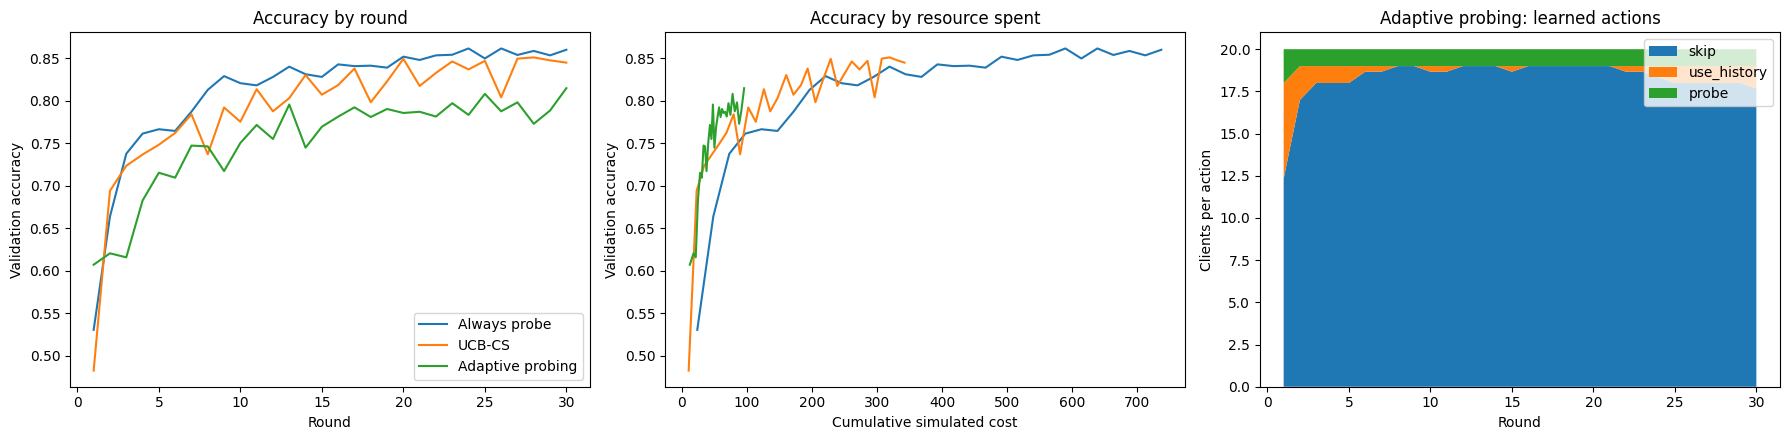

In [13]:
def mean_curve(runs, column):
    return pd.concat([df[column] for df, _ in runs], axis=1).mean(axis=1).to_numpy()


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for name, runs in results.items():
    rounds = runs[0][0]["round"].to_numpy()
    accuracy = mean_curve(runs, "val_accuracy")
    cumulative_cost = mean_curve(runs, "cumulative_cost")
    axes[0].plot(rounds, accuracy, label=name)
    axes[1].plot(cumulative_cost, accuracy, label=name)

axes[0].set_xlabel("Round")
axes[0].set_ylabel("Validation accuracy")
axes[0].set_title("Accuracy by round")
axes[1].set_xlabel("Cumulative simulated cost")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Accuracy by resource spent")
axes[0].legend()

adaptive_runs = results[adaptive.name]
rounds = adaptive_runs[0][0]["round"].to_numpy()
axes[2].stackplot(
    rounds,
    mean_curve(adaptive_runs, "num_skip"),
    mean_curve(adaptive_runs, "num_use_history"),
    mean_curve(adaptive_runs, "num_probe"),
    labels=ACTION_NAMES,
)
axes[2].set_xlabel("Round")
axes[2].set_ylabel("Clients per action")
axes[2].set_title("Adaptive probing: learned actions")
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()